# فراهم کردن پیش نیاز ها ، شامل آدرس ها و فراخوانی ها

In [67]:
#=======imports========
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

#========root========
ROOT = Path.cwd().resolve().parent

#=======require-paths========
report_path = ROOT / "reports" / "preprocess"
report_path.mkdir(parents=True, exist_ok=True)

raw_data_path = ROOT / "data" / "raw_data" / "digikala-comments.csv"

clean_data_path = ROOT / "data" / "clean_data"
clean_data_path.mkdir(parents=True, exist_ok=True)

## لود کردن دیتاست 

In [68]:
#======load-dataset========
try:
    df = pd.read_csv(raw_data_path)
except FileNotFoundError:
    print(f"File not found:\n{raw_data_path}")

### دیتاست ریسرچ برای بررسی های متفاوت

In [69]:
df_reasearch = df.loc[:,["id","body","rate","recommendation_status","created_at","is_buyer"]]
df_reasearch.head()


,id,body,rate,recommendation_status,created_at,is_buyer
0,53672599,به درد نمیخوره,1.0,not_recommended,23 شهریور 1402,True
1,9897229,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,0.0,recommended,16 تیر 1399,True
2,38074516,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,0.0,recommended,26 مرداد 1401,True
3,18628562,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,0.0,recommended,28 اسفند 1399,True
4,53301258,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,3.0,recommended,12 شهریور 1402,True


In [70]:
duplicate_mask = df_reasearch.duplicated(keep="first")

print("تعداد ردیف‌های تکراری:", duplicate_mask.sum())
print("ایندکس‌ها:", df_reasearch.index[duplicate_mask].tolist())

display(df_reasearch.loc[duplicate_mask].sort_values("id"))


duplicate_indices_to_remove = df_reasearch.index[
    df_reasearch.duplicated(keep="first")
]

df_reasearch = df_reasearch.loc[
    ~df_reasearch.index.isin(duplicate_indices_to_remove)
].copy()

تعداد ردیف‌های تکراری: 2914
ایندکس‌ها: [91337, 104126, 139193, 139194, 139876, 143031, 174537, 258402, 258403, 258404, 258405, 258406, 258407, 258408, 258409, 258410, 258411, 258412, 258413, 258414, 258529, 274802, 304457, 308652, 334942, 334946, 336444, 336445, 336446, 336448, 344131, 344829, 359546, 425462, 425463, 425464, 425465, 425466, 425467, 425468, 425469, 425470, 425471, 425472, 425473, 425474, 425475, 425476, 425477, 425478, 425479, 425480, 425481, 425482, 425784, 440123, 440268, 442252, 474542, 474543, 477403, 477952, 480490, 501063, 515706, 593994, 593995, 593996, 593997, 593998, 593999, 594000, 594001, 594002, 594003, 594004, 594005, 594006, 594007, 594008, 594009, 594010, 594011, 594012, 594013, 594014, 594313, 609160, 640286, 640287, 646572, 672828, 674890, 676835, 684514, 762617, 762618, 762619, 762620, 762621, 762622, 762623, 762624, 762625, 762626, 762627, 762628, 762629, 762630, 762631, 762632, 762633, 762634, 762635, 762636, 762637, 762638, 762639, 762640, 762641, 7

,id,body,rate,recommendation_status,created_at,is_buyer
1603315,1002211,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکن...,3.00,NaN,2 مرداد 1395,False
1267069,1123478,یکی از مهمترین مزایای کتاب صوتی قابل استفاده ب...,0.00,NaN,23 آبان 1395,False
593999,1153354,تنها میتونم بگم این کتاب فوق العاده س.\r\nمن ب...,5.00,NaN,23 آذر 1395,False
1603314,1162097,این یکی از شیرین ترین داشتان هاییهکه خوندم، مث...,4.15,NaN,1 دی 1395,False
930958,1186549,بسیار عالی بود. کیفیت صدا بسیار خوب بود.\r\nپس...,4.75,NaN,18 دی 1395,False
...,...,...,...,...,...,...
2463665,54667339,امروز به دستم رسید با این رنج قیمت بسیار راضی ...,5.00,recommended,24 مهر 1402,True
5369020,54671084,عالی از هر نظر فقط ی بدی داره که یکم کجه,5.00,recommended,24 مهر 1402,True
5369018,54680206,عالی بوووووود,5.00,recommended,24 مهر 1402,True
5369017,54687875,عالی,5.00,recommended,24 مهر 1402,True


# استخراج ستون های ضروری

In [71]:
df_small = df[["body","rate","recommendation_status"]].copy(deep=True)


print(f"تعداد ردیف‌های اولیه: {len(df_small):,}")
df_small = df_small.loc[
    ~df_small.index.isin(duplicate_indices_to_remove)
].copy()

print(f"تعداد ردیف‌های حذف‌شده: {len(duplicate_indices_to_remove):,}")
print(f"تعداد ردیف‌های باقی‌مانده: {len(df_small):,}")

تعداد ردیف‌های اولیه: 6,156,289
تعداد ردیف‌های حذف‌شده: 2,914
تعداد ردیف‌های باقی‌مانده: 6,153,375


### بررسی چند سطر از دیتاست 

In [72]:
display(df_small.head())

,body,rate,recommendation_status
0,به درد نمیخوره,1.0,not_recommended
1,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,0.0,recommended
2,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,0.0,recommended
3,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,0.0,recommended
4,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,3.0,recommended


### فراخوانی اینفو ، جهت بررسی دیتاتایپ ، حجم مصرفی و تعداد سطر ها

In [73]:
print(df_small.info())

<class 'pandas.DataFrame'>
Index: 6153375 entries, 0 to 6156288
Data columns (total 3 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   body                   str    
 1   rate                   float64
 2   recommendation_status  str    
dtypes: float64(1), str(2)
memory usage: 187.8 MB
None


### فراوانی هر رده امتیاز محصول و همچنین سهم داده های مفقود

In [74]:
out_of_range = df.loc[
    df["rate"].notna() & ~df["rate"].between(0, 5),
    ["rate", "body", "recommendation_status"]
]

print("تعداد امتیازهای خارج از بازهٔ ۰ تا ۵:", len(out_of_range))
out_of_range.head(10)


تعداد امتیازهای خارج از بازهٔ ۰ تا ۵: 1


,rate,body,recommendation_status
4369260,2500.0,کوچک و با کیفیت,recommended


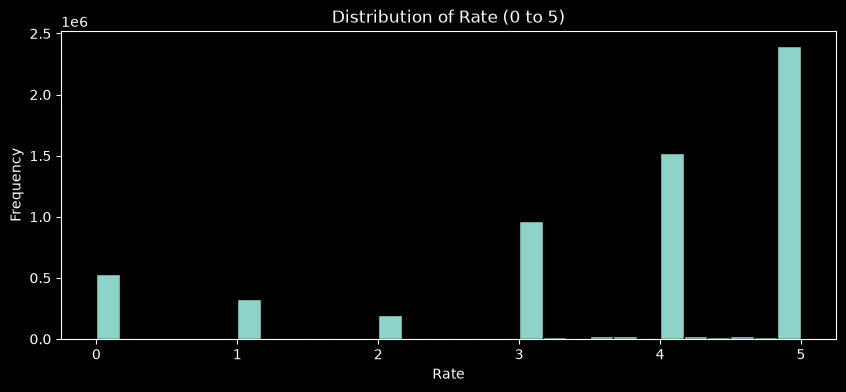

In [75]:
valid_rates = df.loc[df["rate"].between(0, 5), "rate"]

valid_rates.plot.hist(
    bins=30,
    figsize=(10, 4),
    edgecolor="black"
)

plt.title("Distribution of Rate (0 to 5)")
plt.xlabel("Rate")
plt.ylabel("Frequency")
plt.show()


### فراوانی وضعیت پیشنهاد محصول و همچنین سهم داده های مفقود

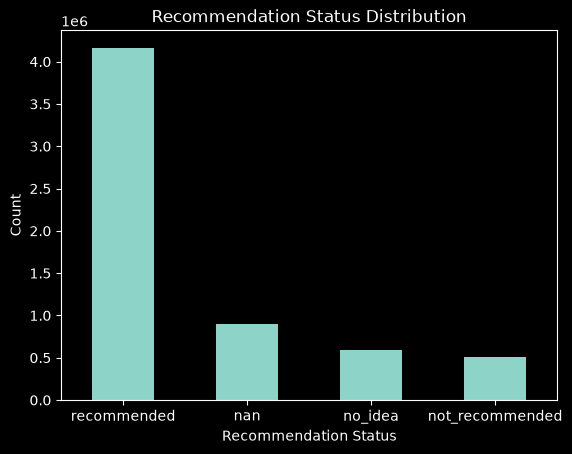

In [76]:
df_small["recommendation_status"].value_counts(dropna=False).plot(kind="bar")
plt.title("Recommendation Status Distribution")
plt.xlabel("Recommendation Status")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


### بررسی کل رکورد های مفقود برای هر ستون

In [77]:
missing = pd.DataFrame({
    "nan_count": df_small.isna().sum(),
    "nan_percent": df_small.isna().mean().mul(100).round(2)
})

missing


,nan_count,nan_percent
body,637,0.01
rate,0,0.00
recommendation_status,894103,14.53


### آیا نمره 0 تا 5 واقعا مقدار مفقود ندارد؟

In [78]:
rate = pd.to_numeric(df_reasearch["rate"], errors="coerce")
zero = df_reasearch.loc[rate.eq(0)].copy()

print(f"تعداد rate صفر: {len(zero):,}")
print("\nوضعیت پیشنهاد در کامنت‌های با نمره صفر:")
display(zero["recommendation_status"].fillna("مفقود").value_counts())
#
print("\nis_buyer در کامنت‌های صفر:")
display(zero["is_buyer"].fillna("مفقود").value_counts())

display(zero[["created_at", "body", "recommendation_status", "is_buyer"]].head(5))


تعداد rate صفر: 529,026

وضعیت پیشنهاد در کامنت‌های با نمره صفر:


recommendation_status
recommended        425685
not_recommended     57415
مفقود               25358
no_idea             20568
Name: count, dtype: int64


is_buyer در کامنت‌های صفر:


is_buyer
True     514617
False     14409
Name: count, dtype: int64

,created_at,body,recommendation_status,is_buyer
1,16 تیر 1399,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,recommended,True
2,26 مرداد 1401,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,recommended,True
3,28 اسفند 1399,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,recommended,True
22,18 دی 1399,در کل نسبت به پولی که پرداخت میکنید خوبه,recommended,True
28,9 اردیبهشت 1399,خوب بود,recommended,True


### بررسی رابطه و توزیع دو ویژگی وضعیت پیشنهاد و نمره عددی

Missing rate values: 0
Rates outside [0, 5] or non-numeric: 1


,count,mean,median,q25,q75
recommendation_group,,,,,
not_recommended,504529,1.45,1.0,1.0,2.0
recommended,4160990,3.93,4.0,4.0,5.0
missing_label,894103,4.04,4.0,4.0,5.0
no_idea,593752,2.92,3.0,3.0,3.0


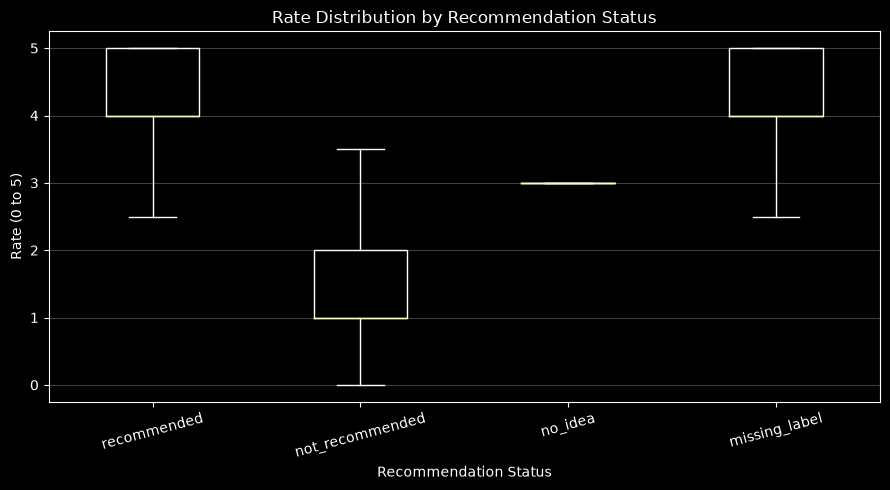

In [79]:
# Convert rate to numeric without changing the original DataFrame
rate = pd.to_numeric(df_small["rate"], errors="coerce")

# Keep only rates in the expected range for this comparison
valid_mask = rate.between(0, 5)
invalid_mask = df_small["rate"].notna() & ~valid_mask

analysis = df_small.loc[
    valid_mask, ["recommendation_status"]
].copy()

analysis["rate"] = rate.loc[valid_mask]

# Represent missing labels explicitly for analysis and visualization
analysis["recommendation_group"] = (
    analysis["recommendation_status"]
    .fillna("missing_label")
    .astype(str)
)

print(f"Missing rate values: {df_small['rate'].isna().sum():,}")
print(f"Rates outside [0, 5] or non-numeric: {invalid_mask.sum():,}")

# Summarize the rate distribution for each recommendation group
summary = (
    analysis.groupby("recommendation_group", sort=False)["rate"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        q25=lambda values: values.quantile(0.25),
        q75=lambda values: values.quantile(0.75),
    )
    .round(2)
)

display(summary)

# Compare medians and spreads; hide outlier markers to keep the plot readable
group_order = [
    "recommended",
    "not_recommended",
    "no_idea",
    "missing_label",
]
group_order = [
    group for group in group_order
    if group in analysis["recommendation_group"].values
]

plot_values = [
    analysis.loc[
        analysis["recommendation_group"] == group, "rate"
    ]
    for group in group_order
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(plot_values, showfliers=False)
ax.set_xticks(range(1, len(group_order) + 1))
ax.set_xticklabels(group_order, rotation=15)
ax.set_title("Rate Distribution by Recommendation Status")
ax.set_xlabel("Recommendation Status")
ax.set_ylabel("Rate (0 to 5)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


### بررسی طول نظر ها

In [80]:
df_small["word_count"] = df_small["body"].fillna("").str.split().str.len()

df_small["word_count"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)


count    6.153375e+06
mean     1.008228e+01
std      1.335001e+01
min      0.000000e+00
25%      3.000000e+00
50%      6.000000e+00
75%      1.200000e+01
90%      2.200000e+01
95%      3.200000e+01
99%      6.200000e+01
max      9.080000e+02
Name: word_count, dtype: float64

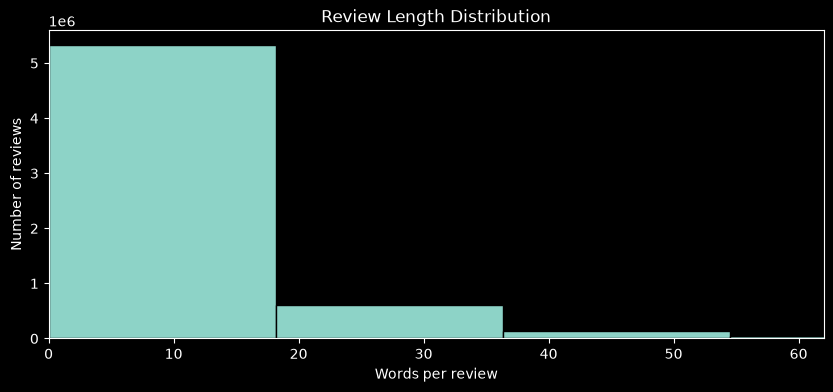

In [81]:
upper = df_small["word_count"].quantile(0.99)

df_small["word_count"].plot.hist(
    bins=50,
    figsize=(10, 4),
    edgecolor="black"
)

plt.xlim(0, upper)
plt.title("Review Length Distribution")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.show()


### بررسی کاراکتر های یکتا

In [82]:

char_counts = Counter()

for text in df_small["body"].dropna().astype(str):
    char_counts.update(text)

print("تعداد کاراکترهای یکتا:", len(char_counts))
for char, count in char_counts.items():
    print(f"{char:15}\n{count:15,}\n=====")


تعداد کاراکترهای یکتا: 1304
ب              
     15,023,997
=====
ه              
     15,470,026
=====
               
     56,606,701
=====
د              
     14,483,811
=====
ر              
     14,888,428
=====
ن              
     14,109,240
=====
م              
     14,999,389
=====
ی              
     25,674,457
=====
خ              
      7,021,453
=====
و              
     17,449,323
=====
‌              
        295,417
=====
ت              
     11,411,946
=====
س              
      7,668,454
=====
ع              
      3,195,174
=====
ا              
     26,004,383
=====
ک              
      8,105,217
=====
ل              
      7,853,690
=====
ف              
      3,686,510
=====
گ              
      2,599,797
=====
ش              
      7,341,686
=====
              
        516,172
=====

              
        934,245
=====
غ              
        229,423
=====
ز              
      3,951,148
=====
ژ              
        114,221
=====
ظ              
       

### نرمال کردن حروف فارسی عربی

In [83]:
for char in ["ي", "ك"]:
    print(repr(char), df_small["body"].str.count(char).sum())

translation = str.maketrans({
    "ي": "ی",
    "ك": "ک",

    # ارقام فارسی → لاتین
    "۰": "0", "۱": "1", "۲": "2", "۳": "3", "۴": "4",
    "۵": "5", "۶": "6", "۷": "7", "۸": "8", "۹": "9",

    # ارقام عربی → لاتین
    "٠": "0", "١": "1", "٢": "2", "٣": "3", "٤": "4",
    "٥": "5", "٦": "6", "٧": "7", "٨": "8", "٩": "9",

    # حذف کشیده و علائم نامرئی جهت متن
    "ـ": "",
    "\u200e": "",  # LRM
    "\u200f": "",  # RLM
    "\u202a": "", "\u202b": "", "\u202c": "",
    "\u202d": "", "\u202e": "",
    "\u2066": "", "\u2067": "", "\u2068": "", "\u2069": "",
})


df_small["body_normalized"] = (
    df_small["body"]
    .astype("string")
    .str.translate(translation)
)


'ي' 165111.0
'ك' 49236.0


### بررسی دوباره

In [84]:

char_counts = Counter()

for text in df_small["body_normalized"].dropna().astype(str):
    char_counts.update(text)

print("تعداد کاراکترهای یکتا:", len(char_counts))
for char, count in char_counts.items():
    print(f"{char:15}\n{count:15,}\n=====")


تعداد کاراکترهای یکتا: 1274
ب              
     15,023,997
=====
ه              
     15,470,026
=====
               
     56,606,701
=====
د              
     14,483,811
=====
ر              
     14,888,428
=====
ن              
     14,109,240
=====
م              
     14,999,389
=====
ی              
     25,839,568
=====
خ              
      7,021,453
=====
و              
     17,449,323
=====
‌              
        295,417
=====
ت              
     11,411,946
=====
س              
      7,668,454
=====
ع              
      3,195,174
=====
ا              
     26,004,383
=====
ک              
      8,154,453
=====
ل              
      7,853,690
=====
ف              
      3,686,510
=====
گ              
      2,599,797
=====
ش              
      7,341,686
=====
              
        516,172
=====

              
        934,245
=====
غ              
        229,423
=====
ز              
      3,951,148
=====
ژ              
        114,221
=====
ظ              
       

> دو کارکتر عربی با نسخه فارسی جایگزین شدند و تمام اعداد فارسی و عربی با لاتین عوض شد همچنین کاراکتر های نامرئی و... که اهمیت انتقال احساس رو به خطر نمی انداخت رو جایگزین کردم